# Sitios objetivo en la Luna y Marte (v0)
**NASA Space Apps Challenge 2026** · Los lugares de la Luna y Marte para los que buscamos análogos en la Tierra.

| Cuerpo | Sitios | Fuente | Geometría |
|---|---|---|---|
| Luna | 9 regiones candidatas de aterrizaje de Artemis (polo sur) | USGS ScienceBase: rejillas LGRS de las 9 regiones (origen: LROC QuickMap) | contorno de cada región |
| Luna | 6 alunizajes Apollo (tripulados) | LROC (2016), sistema Mean Earth | punto |
| Luna y Marte | Aterrizajes robóticos con éxito (landers y rovers) y 2 planificados con sitio elegido | ver tabla de la sección 3 | punto |
| Marte | Exploration Zones (EZ) propuestas en el taller de NASA de 2015 | tabla de OpenPlanetary (47 EZ, recopilada de NASA); si no responde, 12 EZ con coordenadas sacadas de los resúmenes del taller | punto + radio de 100 km (definición de EZ) |

**Nota sobre Artemis**: en febrero de 2026 NASA cambió el plan: Artemis III probará el módulo de aterrizaje en órbita terrestre (2027) y el
primer alunizaje pasa a Artemis IV (2028). Las 9 regiones siguen siendo las candidatas del polo sur (actualización LPSC 2026).

**Salidas**: `06_web/sitios_v0/sitios.geojson` (+ `manifest.json` y bloque `capas.sitios` del manifest común) y
`03_datos/procesados/sitios_luna_polar.gpkg` (regiones en proyección polar, para la topografía de los sitios).

## 0. Instalación

In [1]:
!pip install -q pyogrio

## 1. Configuración

In [2]:
import os, re, io, json, glob, time, zipfile, datetime
import numpy as np, pandas as pd, requests, geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point, mapping
from shapely.ops import unary_union
from IPython.display import display
from google.colab import drive

drive.mount("/content/drive")
for raiz in ["/content/drive/MyDrive", "/content/drive/My Drive"]:
    if os.path.isdir(raiz):
        break
BASE = f"{raiz}/Hackathon Nasa"
VERSION = "sitios_v0"
BRUTOS, PROC = f"{BASE}/03_datos/brutos/sitios", f"{BASE}/03_datos/procesados"
WEB, RES = f"{BASE}/06_web/{VERSION}", f"{BASE}/04_resultados/{VERSION}"
for d in (BRUTOS, PROC, WEB, RES):
    os.makedirs(d, exist_ok=True)
SB_ITEM = "671a6fa8d34efed5620f89f8"     # USGS ScienceBase: rejillas LGRS de las 9 regiones Artemis
SB = "https://www.sciencebase.gov/catalog"
REGIONES_ARTEMIS = ["Peak Near Cabeus B", "Haworth", "Malapert Massif", "Mons Mouton Plateau", "Mons Mouton",
                    "Nobile Rim 1", "Nobile Rim 2", "de Gerlache Rim 2", "Slater Plain"]
print(BASE)

Mounted at /content/drive
/content/drive/MyDrive/Hackathon Nasa


## 2. Luna: regiones Artemis (USGS ScienceBase)
Se usan los contornos oficiales de las 9 regiones (`A3_9regions-lonlat-simplified.zip`). Si faltara alguna, se reconstruye
uniendo las celdas de su rejilla de 1 km. Las descargas se guardan en `03_datos/brutos/sitios/` y no se repiten.

In [3]:
def json_sb(url):
    r = requests.get(url, params={"format": "json"}, timeout=60)
    r.raise_for_status()
    return r.json()

def urls_de(f, item_id):
    """Todas las direcciones de descarga posibles de un archivo de ScienceBase (la primera que dé un archivo válido gana)."""
    cand = [f.get("downloadUri"), f.get("url")]
    cand += [v for k, v in f.items() if isinstance(v, str) and v.startswith("http") and re.search(r"ur[il]", k, re.I)]
    cand.append(f"{SB}/file/get/{item_id}?name={requests.utils.quote(f['name'])}")
    vistos = []
    for u in cand:
        if u and u not in vistos:
            vistos.append(u)
    return vistos

def archivos_sb(item):
    """Todos los archivos de un item de ScienceBase (incluidos los de sus 'facets' y sus items hijos): [(nombre, [urls])]."""
    fs = list(item.get("files", []))
    for fa in item.get("facets", []):
        fs += fa.get("files", [])
    out = [(f["name"], urls_de(f, item["id"])) for f in fs]
    if not out and item.get("hasChildren"):
        hijos = requests.get(f"{SB}/items", params={"parentId": item["id"], "format": "json", "max": 200}, timeout=60).json()
        for h in hijos.get("items", []):
            out += archivos_sb(json_sb(f"{SB}/item/{h['id']}"))
    return out

def region_de(nombre):
    clave = re.sub(r"[^a-z0-9]", "", nombre.lower())
    for r in sorted(REGIONES_ARTEMIS, key=len, reverse=True):      # 'Mons Mouton Plateau' antes que 'Mons Mouton'
        if re.sub(r"[^a-z0-9]", "", r.lower()) in clave:
            return r
    return None

def valido(ruta, nombre):
    if not os.path.exists(ruta) or os.path.getsize(ruta) == 0:
        return False
    return zipfile.is_zipfile(ruta) if nombre.lower().endswith(".zip") else True

def descargar(nombre, urls):
    """Descarga probando cada dirección; descarta respuestas que no son el archivo (p. ej. una página HTML)."""
    ruta = f"{BRUTOS}/{nombre}"
    if valido(ruta, nombre):
        return ruta
    if os.path.exists(ruta):
        os.remove(ruta)                                   # copia mala de un intento anterior
    errores = []
    for u in urls:
        try:
            with requests.get(u, stream=True, timeout=300, headers={"User-Agent": "Mozilla/5.0 (Colab; NASA Space Apps)"}) as r:
                tipo = r.headers.get("Content-Type", "?")
                with open(ruta, "wb") as f:
                    for t in r.iter_content(1 << 20):
                        f.write(t)
            if r.status_code == 200 and valido(ruta, nombre):
                return ruta
            inicio = open(ruta, "rb").read(120)
            errores.append(f"{u[:80]} -> HTTP {r.status_code}, {tipo}, empieza por {inicio[:60]!r}")
        except requests.RequestException as e:
            errores.append(f"{u[:80]} -> {e!r}")
        if os.path.exists(ruta):
            os.remove(ruta)
    raise RuntimeError(f"No pude descargar {nombre}:\n  " + "\n  ".join(errores))

item = json_sb(f"{SB}/item/{SB_ITEM}")
todos = archivos_sb(item)
print(f"ScienceBase: «{item.get('title', '')[:90]}» · {len(todos)} archivos")
GEO_LUNA_DEF = "+proj=longlat +R=1737400 +no_defs"          # si algún archivo no trae .prj

def leer_zip(ruta):
    """Lee todos los shapefiles de un zip (también dentro de carpetas)."""
    with zipfile.ZipFile(ruta) as z:
        shps = [x for x in z.namelist() if x.lower().endswith(".shp")]
    out = []
    for s in shps:
        g = gpd.read_file(f"zip://{ruta}!{s}")
        if g.crs is None:
            g = g.set_crs(GEO_LUNA_DEF)
        out.append((s, g))
    return out

capas = []
# 1) Contornos oficiales de las 9 regiones en lon/lat (un solo zip)
contorno = [(n, u) for n, u in todos if "lonlat" in n.lower() and n.lower().endswith(".zip")]
for n, u in contorno:
    for s, g in leer_zip(descargar(n, u)):
        col = next((c for c in g.columns if c != "geometry" and not pd.api.types.is_numeric_dtype(g[c])
                    and g[c].astype(str).map(lambda v: region_de(v) is not None).any()), None)
        if col:
            for k in range(len(g)):
                reg = region_de(str(g[col].iloc[k]))
                if reg:
                    capas.append((reg, g.iloc[[k]]))
        elif region_de(s):
            capas.append((region_de(s), g))
ORIGEN_GEOM = f"contornos de las regiones ({contorno[0][0]})" if capas else None

# 2) Si faltan regiones: zips por región con las rejillas (se usa la más gruesa: 1 km)
faltan = [r for r in REGIONES_ARTEMIS if r not in {c[0] for c in capas}]
if faltan:
    for n, u in todos:
        reg = region_de(n)
        if reg in faltan and n.lower().endswith(".zip"):
            leidas = leer_zip(descargar(n, u))
            for resol in ("1km", "100m", "10m"):
                sel = [(s, g) for s, g in leidas if resol in s.lower().replace("_", "")]
                if sel:
                    break
            capas += [(reg, g) for s, g in (sel or leidas)]
    ORIGEN_GEOM = (ORIGEN_GEOM + " + " if ORIGEN_GEOM else "") + "rejillas LGRS por región"
assert capas, "No encuentro las regiones en ScienceBase; archivos: " + str([n for n, _ in todos])

from pyproj import CRS
crs_origen = {str(g.crs) for _, g in capas}
R_LUNA = capas[0][1].crs.geodetic_crs.ellipsoid.semi_major_metre
# Todo se pasa a una estereográfica polar sur común (las rejillas pueden venir en LTM, LPS o lon/lat)
CRS_POLAR = CRS.from_proj4(f"+proj=stere +lat_0=-90 +lon_0=0 +k=1 +x_0=0 +y_0=0 +R={R_LUNA} +units=m +no_defs")
print(f"Geometría: {ORIGEN_GEOM} · regiones encontradas: {len({c[0] for c in capas})}/9 · "
      f"{len(crs_origen)} sistema(s) de coordenadas · radio lunar {R_LUNA:.0f} m")

ScienceBase: «Down Selected Artemis III Candidate Landing Site Navigational Grids» · 11 archivos
Geometría: contornos de las regiones (A3_9regions-lonlat-simplified.zip) · regiones encontradas: 9/9 · 1 sistema(s) de coordenadas · radio lunar 1737400 m


In [4]:
filas = []
for region in REGIONES_ARTEMIS:
    partes = [g.to_crs(CRS_POLAR) for r, g in capas if r == region]
    if not partes:
        print("  ⚠ sin geometría:", region); continue
    geom = unary_union([unary_union(p.geometry.values) for p in partes])
    filas.append({"region": region, "geometry": geom, "area_km2": round(geom.area / 1e6, 1)})
artemis_polar = gpd.GeoDataFrame(filas, geometry="geometry", crs=CRS_POLAR)
geo_luna = CRS_POLAR.geodetic_crs                       # geográficas lunares (la esfera de 1737,4 km de la rejilla)
artemis = artemis_polar.to_crs(geo_luna)
centros = gpd.GeoSeries(artemis_polar.geometry.centroid, crs=CRS_POLAR).to_crs(geo_luna)
artemis["lat_centro"], artemis["lon_centro"] = centros.y.round(4), (((centros.x + 180) % 360) - 180).round(4)
artemis_polar.to_file(f"{PROC}/sitios_luna_polar.gpkg", driver="GPKG")
display(artemis.drop(columns="geometry"))

,region,area_km2,lat_centro,lon_centro
0,Peak Near Cabeus B,399.8,-83.6375,-68.7495
1,Haworth,888.0,-86.7639,-22.7770
2,Malapert Massif,441.0,-85.9948,-0.2358
3,Mons Mouton Plateau,4451.8,-84.3347,30.5923
4,Mons Mouton,256.0,-85.4266,31.7428
5,Nobile Rim 1,400.0,-85.4364,37.3470
6,Nobile Rim 2,400.0,-83.9541,58.8215
7,de Gerlache Rim 2,400.0,-88.2300,-64.6284
8,Slater Plain,399.8,-87.1637,125.5377


## 3. Aterrizajes ya realizados (y planificados) en la Luna y Marte
Lugares donde ya se ha aterrizado: son terreno comprobado sobre el terreno (y, en los rovers, recorrido y analizado), así que sirven
de referencia junto a los sitios objetivo.

| Tipo | Fuente de las coordenadas |
|---|---|
| Apollo (tripulados) | LROC (2016), Coordinates of Human Features, sistema Mean Earth |
| Robóticos en la Luna | Wikipedia, *List of artificial objects on the Moon* (cita LROC); los anteriores a 2016 coinciden con LROC (2016) |
| Robóticos en Marte | Wikipedia, *List of Mars landers*, comprobado con la tabla de sitios de ODE/PDS (Viking, Pathfinder, Spirit, Opportunity, Phoenix, Curiosity) e InSight con Golombek et al. (2020) |
| Planificados | Rosalind Franklin (ESA, Oxia Planum, aterrizaje previsto en 2030) y Chang'e 7 (CNSA, cresta de Shackleton, lanzamiento aplazado) |

Solo se incluyen aterrizajes suaves (no impactos). IM-1 e IM-2 quedaron tumbados y Luna 23 volcó: se marcan en `nota`.

In [5]:
APOLLO = pd.DataFrame([["Apollo 11", 0.67416, 23.47314, "mar (Mare Tranquillitatis)", "1969"],
                       ["Apollo 12", -3.0128, 336.5781, "mar (Oceanus Procellarum)", "1969"],
                       ["Apollo 14", -3.64589, 342.52806, "tierras altas (Fra Mauro)", "1971"],
                       ["Apollo 15", 26.13239, 3.63330, "mar y montaña (Hadley-Apennine)", "1971"],
                       ["Apollo 16", -8.9734, 15.5011, "tierras altas (Descartes)", "1972"],
                       ["Apollo 17", 20.1911, 30.7723, "valle (Taurus-Littrow)", "1972"]],
                      columns=["sitio", "lat", "lon_este", "terreno", "fecha"])
APOLLO["lon"] = ((APOLLO.lon_este + 180) % 360) - 180

WIKI_LUNA = "https://en.wikipedia.org/wiki/List_of_artificial_objects_on_the_Moon"
WIKI_MARTE = "https://en.wikipedia.org/wiki/List_of_Mars_landers"
ODE_MARTE = "https://ode.rsl.wustl.edu/mars/pagehelp/Content/Missions_Instruments/Landing_Sites.htm"
# misión, cuerpo, agencia, fecha, lat, lon (este −180..180), rover, nota, fuente
ROBOTICOS = [
    ("Luna 9", "luna", "URSS", "1966", 7.0833, -64.3667, "", "", WIKI_LUNA),
    ("Luna 13", "luna", "URSS", "1966", 18.8667, -62.05, "", "", WIKI_LUNA),
    ("Surveyor 1", "luna", "NASA", "1966", -2.4739, -43.3389, "", "", WIKI_LUNA),
    ("Surveyor 3", "luna", "NASA", "1967", -3.0150, -23.4181, "", "Apollo 12 aterrizó a ~180 m", WIKI_LUNA),
    ("Surveyor 5", "luna", "NASA", "1967", 1.4611, 23.1950, "", "", WIKI_LUNA),
    ("Surveyor 6", "luna", "NASA", "1967", 0.4742, -1.4275, "", "", WIKI_LUNA),
    ("Surveyor 7", "luna", "NASA", "1968", -40.9800, -11.5139, "", "borde del cráter Tycho (tierras altas)", WIKI_LUNA),
    ("Luna 16", "luna", "URSS", "1970", -0.6833, 56.3000, "", "retorno de muestras", WIKI_LUNA),
    ("Luna 17", "luna", "URSS", "1970", 38.2833, -35.0000, "Lunokhod 1", "", WIKI_LUNA),
    ("Luna 20", "luna", "URSS", "1972", 3.5667, 56.5000, "", "retorno de muestras", WIKI_LUNA),
    ("Luna 21", "luna", "URSS", "1973", 25.8500, 30.4500, "Lunokhod 2", "", WIKI_LUNA),
    ("Luna 23", "luna", "URSS", "1974", 12.7500, 62.2000, "", "volcó al aterrizar; no tomó muestras", WIKI_LUNA),
    ("Luna 24", "luna", "URSS", "1976", 12.7500, 62.2000, "", "retorno de muestras; a pocos km de Luna 23", WIKI_LUNA),
    ("Chang'e 3", "luna", "CNSA", "2013", 44.1167, -19.5167, "Yutu", "", WIKI_LUNA),
    ("Chang'e 4", "luna", "CNSA", "2019", -45.4561, 177.5886, "Yutu-2", "cara oculta (cráter Von Kármán)", WIKI_LUNA),
    ("Chang'e 5", "luna", "CNSA", "2020", 43.0575, -51.9161, "", "retorno de muestras", WIKI_LUNA),
    ("Chang'e 6", "luna", "CNSA", "2024", -41.6386, -153.9853, "", "retorno de muestras de la cara oculta", WIKI_LUNA),
    ("Chandrayaan-3", "luna", "ISRO", "2023", -69.3731, 32.3189, "Pragyan", "el aterrizaje más cercano al polo sur hasta 2024", WIKI_LUNA),
    ("SLIM", "luna", "JAXA", "2024", -13.3161, 25.2511, "LEV-1, LEV-2", "quedó apoyado de lado", WIKI_LUNA),
    ("IM-1 Odysseus", "luna", "Intuitive Machines (NASA CLPS)", "2024", -84.9000, 12.9000, "", "quedó inclinado; región del polo sur", WIKI_LUNA),
    ("Blue Ghost M1", "luna", "Firefly (NASA CLPS)", "2025", 18.5622, 61.8103, "", "Mare Crisium", WIKI_LUNA),
    ("IM-2 Athena", "luna", "Intuitive Machines (NASA CLPS)", "2025", -84.7906, 29.1958, "", "volcó al aterrizar; región del polo sur", WIKI_LUNA),
    ("Mars 3", "marte", "URSS", "1971", -45.0, -158.0, "PrOP-M", "posición estimada; transmitió solo ~20 s", WIKI_MARTE),
    ("Viking 1", "marte", "NASA", "1976-07-20", 22.27, -47.95, "", "Chryse Planitia", ODE_MARTE),
    ("Viking 2", "marte", "NASA", "1976-09-03", 47.64, 134.29, "", "Utopia Planitia", ODE_MARTE),
    ("Mars Pathfinder", "marte", "NASA", "1997-07-04", 19.13, -33.3033, "Sojourner", "Ares Vallis", ODE_MARTE),
    ("Spirit (MER-A)", "marte", "NASA", "2004-01-04", -14.5684, 175.4726, "Spirit", "cráter Gusev", ODE_MARTE),
    ("Opportunity (MER-B)", "marte", "NASA", "2004-01-25", -1.9462, -5.5257, "Opportunity", "Meridiani Planum", ODE_MARTE),
    ("Phoenix", "marte", "NASA", "2008-05-25", 68.22, -125.70, "", "Vastitas Borealis; hielo bajo la superficie", ODE_MARTE),
    ("Curiosity (MSL)", "marte", "NASA", "2012-08-06", -4.5895, 137.4417, "Curiosity", "cráter Gale", ODE_MARTE),
    ("InSight", "marte", "NASA", "2018-11-26", 4.5024, 135.6234, "", "Elysium Planitia (Golombek et al., 2020)", "https://doi.org/10.1029/2020EA001248"),
    ("Perseverance (Mars 2020)", "marte", "NASA", "2021-02-18", 18.4447, 77.4508, "Perseverance, Ingenuity", "cráter Jezero (delta)", WIKI_MARTE),
    ("Tianwen-1", "marte", "CNSA", "2021-05-14", 25.1, 109.7, "Zhurong", "Utopia Planitia", WIKI_MARTE),
]
PLANIFICADOS = [
    ("Rosalind Franklin (ExoMars)", "marte", "ESA", "aterrizaje previsto 2030", 18.20, -24.55, "Rosalind Franklin", "Oxia Planum, elipse elegida en 2018", "https://en.wikipedia.org/wiki/Rosalind_Franklin_(rover)"),
    ("Chang'e 7", "luna", "CNSA", "lanzamiento aplazado (previsto 2027)", -88.80, 123.40, "", "cresta SE del cráter Shackleton (polo sur)", "https://en.wikipedia.org/wiki/Chang%27e_7"),
]
cols = ["mision", "cuerpo", "agencia", "fecha", "lat", "lon", "rover", "nota", "url_fuente"]
aterrizajes = pd.concat([pd.DataFrame(ROBOTICOS, columns=cols).assign(tipo="aterrizaje_robotico"),
                         pd.DataFrame(PLANIFICADOS, columns=cols).assign(tipo="aterrizaje_planificado")], ignore_index=True)
print(aterrizajes.groupby(["cuerpo", "tipo"]).size())
aterrizajes[["mision", "cuerpo", "agencia", "fecha", "lat", "lon", "rover", "nota"]]

cuerpo  tipo                  
luna    aterrizaje_planificado     1
        aterrizaje_robotico       22
marte   aterrizaje_planificado     1
        aterrizaje_robotico       11
dtype: int64


,mision,cuerpo,agencia,fecha,lat,lon,rover,nota
0,Luna 9,luna,URSS,1966,7.0833,-64.3667,,
1,Luna 13,luna,URSS,1966,18.8667,-62.0500,,
2,Surveyor 1,luna,NASA,1966,-2.4739,-43.3389,,
3,Surveyor 3,luna,NASA,1967,-3.0150,-23.4181,,Apollo 12 aterrizó a ~180 m
4,Surveyor 5,luna,NASA,1967,1.4611,23.1950,,
5,Surveyor 6,luna,NASA,1967,0.4742,-1.4275,,
6,Surveyor 7,luna,NASA,1968,-40.9800,-11.5139,,borde del cráter Tycho (tierras altas)
7,Luna 16,luna,URSS,1970,-0.6833,56.3000,,retorno de muestras
8,Luna 17,luna,URSS,1970,38.2833,-35.0000,Lunokhod 1,
9,Luna 20,luna,URSS,1972,3.5667,56.5000,,retorno de muestras


## 4. Marte: Exploration Zones
Se intenta descargar la tabla de OpenPlanetary con las 47 EZ. Si el servicio no responde, se usan las 12 EZ cuyas coordenadas
aparecen en los resúmenes del taller (convertidas a longitud este de −180 a 180).

In [6]:
CACHE_EZ = f"{BRUTOS}/exploration_zones_openplanetary.geojson"
URLS_EZ = ["https://nmanaud.carto.com/api/v2/sql",
           "https://openplanetary.carto.com/user/nmanaud/api/v2/sql"]

def ez_openplanetary():
    if os.path.exists(CACHE_EZ):
        return json.load(open(CACHE_EZ, encoding="utf-8"))
    for u in URLS_EZ:
        try:
            r = requests.get(u, params={"q": "SELECT * FROM opm_mars_explorationzones", "format": "geojson"}, timeout=60)
            gj = r.json() if r.status_code == 200 else None
        except (requests.RequestException, ValueError):
            gj = None
        if gj and len(gj.get("features", [])) >= 30:
            json.dump(gj, open(CACHE_EZ, "w", encoding="utf-8"))
            return gj
    return None

# 12 EZ con centro en los resúmenes del taller de 2015 (número de resumen, nombre, lat, lon este −180..180, cita)
EZ_RESUMENES = [
    (1007, "Eastern Melas Chasma", -11.7, -70.0, "McEwen et al."),
    (1036, "Western Coprates Chasma", -11.684, -66.633, "Mojarro et al."),
    (1019, "Chryse Planitia (Viking 1)", 22.3, -48.3, "Farrell et al."),
    (1054, "Eastern outlet of Valles Marineris", -4.1, -35.2, "Clifford et al."),
    (1023, "Equatorial EZ (Valles Marineris sur)", -18.83, -49.21, "Mitchell et al."),
    (1020, "Gale Crater", -4.5965, 137.4019, "Calef et al."),
    (1042, "SW Sinus Meridiani", -2.2526, -6.4335, "resumen 1042"),
    (1057, "Southern Meridiani Planum", -3.1740, -4.5173, "Clarke et al."),
    (1008, "Gusev Crater", -14.5, 175.4, "Longo et al."),
    (1016, "Zephyria Planum", -1.3717, 157.1417, "Yakovlev"),
    (1043, "Apollinaris Sulci", -12.6667, 176.6667, "Kerber et al."),
    (1012, "Hebrus Valles", 20.0833, 126.6333, "Davila et al."),
]

gj = ez_openplanetary()
if gj:
    ez = gpd.GeoDataFrame.from_features(gj["features"], crs=None)
    col = next((c for c in ez.columns if re.search(r"label|name|nombre|title|zone|site", c, re.I) and not pd.api.types.is_numeric_dtype(ez[c])), None)
    ez["nombre"] = ez[col] if col else [f"EZ {i + 1}" for i in range(len(ez))]
    ez["geometry"] = ez.geometry.centroid
    ez["lon"] = (((ez.geometry.x + 180) % 360) - 180).round(4); ez["lat"] = ez.geometry.y.round(4)
    ez["fuente"] = "OpenPlanetary (N. Manaud), tabla opm_mars_explorationzones, recopilada de NASA"
    ORIGEN_EZ = f"OpenPlanetary ({len(ez)} EZ)"
else:
    ez = pd.DataFrame(EZ_RESUMENES, columns=["resumen", "nombre", "lat", "lon", "autores"])
    ez["fuente"] = ez.apply(lambda r: f"First Landing Site/Exploration Zone Workshop (2015), resumen {r.resumen} ({r.autores})", axis=1)
    ORIGEN_EZ = f"resúmenes del taller de 2015 ({len(ez)} EZ)"
print("Exploration Zones:", ORIGEN_EZ)
ez[["nombre", "lat", "lon", "fuente"]].head(15)

Exploration Zones: OpenPlanetary (47 EZ)


,nombre,lat,lon,fuente
0,E. Melas Chasma,-11.7,-70.0,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
1,Coprates Chasma,-11.7,-66.6,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
2,Viking,22.3,-48.3,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
3,Acidalia Planitia,20.0,-40.0,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
4,NE Marineris,-4.1,-35.2,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
5,SE Marineris,-18.8,-49.2,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
6,Gale Crater,-4.6,137.4,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
7,Gale Crater 2,-4.6,137.0,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
8,Gale Crater 3,-4.7,137.1,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."
9,Sinus Meridiani,-2.3,-6.4,"OpenPlanetary (N. Manaud), tabla opm_mars_expl..."


## 5. Mapa de comprobación

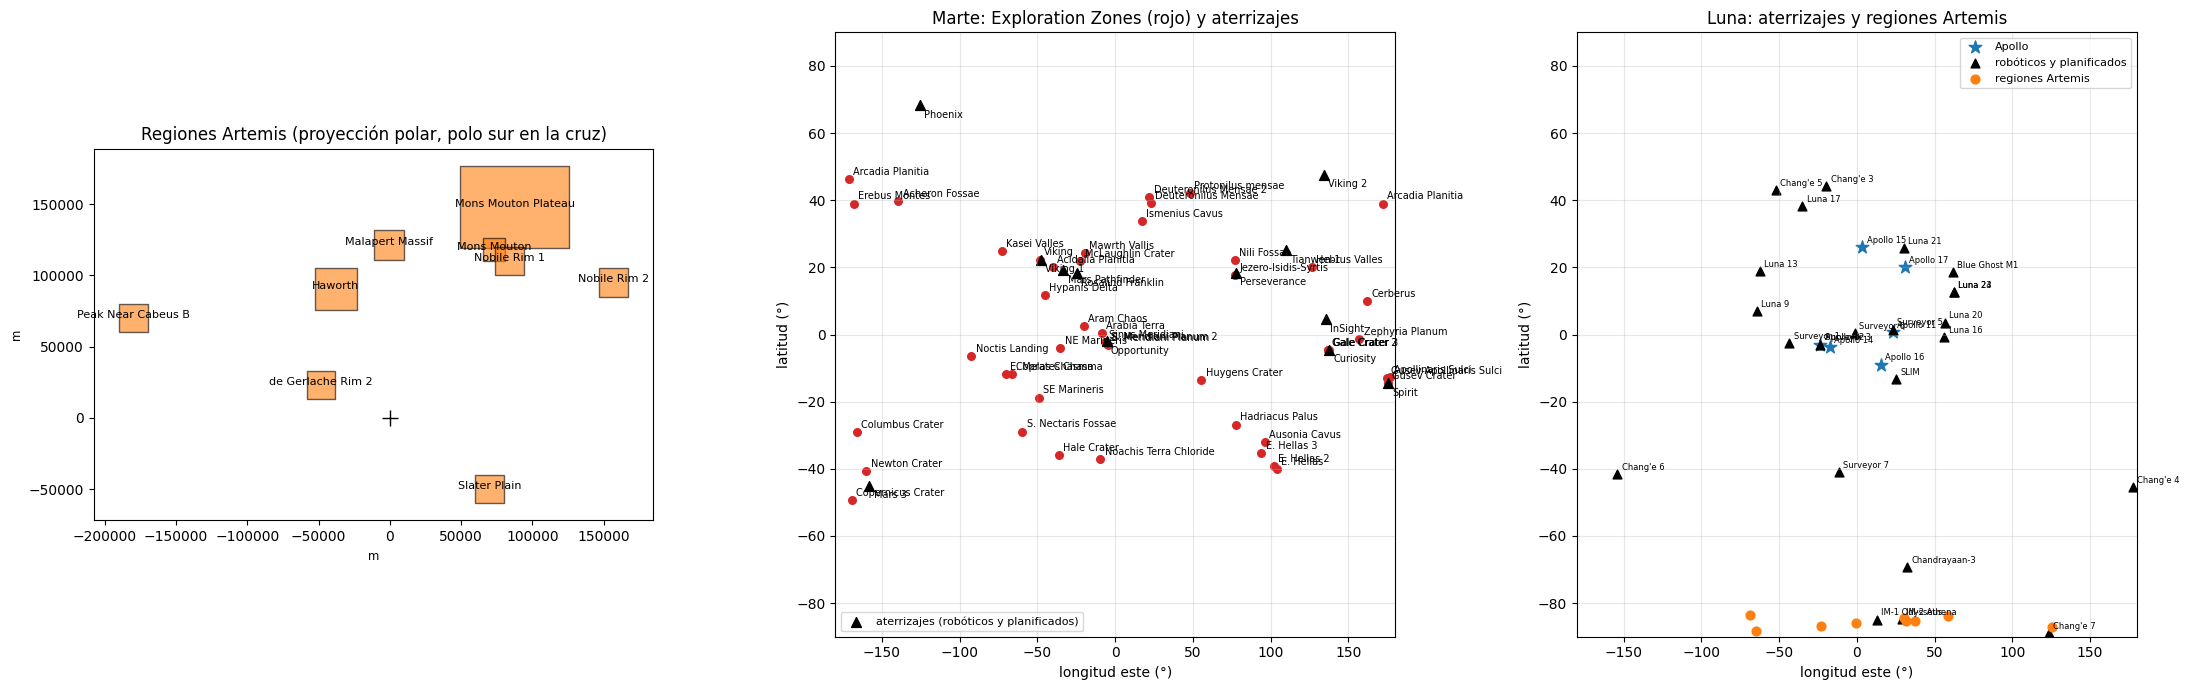

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
ax = axes[0]
artemis_polar.plot(ax=ax, color="tab:orange", alpha=0.6, edgecolor="black")
for r in artemis_polar.itertuples():
    c = r.geometry.centroid; ax.annotate(r.region, (c.x, c.y), fontsize=8, ha="center")
ax.plot(0, 0, "k+", ms=12); ax.set_aspect("equal")
ax.set_title("Regiones Artemis (proyección polar, polo sur en la cruz)"); ax.set_xlabel("m"); ax.set_ylabel("m")
ax = axes[1]
ax.scatter(ez.lon, ez.lat, color="tab:red", s=30)
for r in ez.itertuples():
    ax.annotate(r.nombre, (r.lon, r.lat), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.grid(alpha=0.3)
am = aterrizajes[aterrizajes.cuerpo == "marte"]
ax.scatter(am.lon, am.lat, marker="^", color="black", s=50, label="aterrizajes (robóticos y planificados)")
for r in am.itertuples():
    ax.annotate(r.mision.split(" (")[0], (r.lon, r.lat), fontsize=7, color="black", xytext=(3, -9), textcoords="offset points")
ax.legend(loc="lower left", fontsize=8)
ax.set_title("Marte: Exploration Zones (rojo) y aterrizajes"); ax.set_xlabel("longitud este (°)"); ax.set_ylabel("latitud (°)")
ax = axes[2]
al = aterrizajes[aterrizajes.cuerpo == "luna"]
ax.scatter(APOLLO.lon, APOLLO.lat, marker="*", color="tab:blue", s=90, label="Apollo")
ax.scatter(al.lon, al.lat, marker="^", color="black", s=40, label="robóticos y planificados")
ax.scatter(artemis.lon_centro, artemis.lat_centro, color="tab:orange", s=40, label="regiones Artemis")
for r in pd.concat([APOLLO.rename(columns={"sitio": "mision"}), al]).itertuples():
    ax.annotate(r.mision, (r.lon, r.lat), fontsize=6, xytext=(3, 3), textcoords="offset points")
ax.set_xlim(-180, 180); ax.set_ylim(-90, 90); ax.grid(alpha=0.3); ax.legend(loc="upper right", fontsize=8)
ax.set_title("Luna: aterrizajes y regiones Artemis"); ax.set_xlabel("longitud este (°)"); ax.set_ylabel("latitud (°)")
plt.tight_layout(); fig.savefig(f"{RES}/mapa_sitios.png", dpi=90, bbox_inches="tight"); plt.show()

## 6. Capa para la web
Coordenadas en grados (latitud planetocéntrica, longitud este de −180 a 180) en el sistema de cada cuerpo, no en WGS84.

In [8]:
def limpio(v):
    if isinstance(v, (float, np.floating)): return None if np.isnan(v) else round(float(v), 5)
    if isinstance(v, np.integer): return int(v)
    return v

def redondear(geom, n=4):
    g = mapping(geom)
    def r(c): return [r(x) for x in c] if isinstance(c[0], (list, tuple)) else [round(c[0], n), round(c[1], n)]
    g["coordinates"] = r(g["coordinates"])
    return g

FUENTE_ARTEMIS = f"USGS ScienceBase, Down Selected Artemis III Candidate Landing Site Navigational Grids: {ORIGEN_GEOM} (regiones de LROC QuickMap)"
features = []
for r in artemis.itertuples():
    slug = re.sub(r"[^a-z0-9]+", "-", r.region.lower()).strip("-")
    features.append({"type": "Feature", "geometry": redondear(r.geometry.simplify(0.001)),
                     "properties": {"id": f"artemis-{slug}", "cuerpo": "luna", "tipo": "region_aterrizaje_artemis", "nombre": r.region,
                                    "lat_centro": limpio(r.lat_centro), "lon_centro": limpio(r.lon_centro), "area_km2": limpio(r.area_km2),
                                    "fuente": FUENTE_ARTEMIS, "url_fuente": f"{SB}/item/{SB_ITEM}"}})
for r in APOLLO.itertuples():
    features.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(r.lon, 5), round(r.lat, 5)]},
                     "properties": {"id": "apollo-" + r.sitio.split()[-1], "cuerpo": "luna", "tipo": "aterrizaje_tripulado", "nombre": r.sitio,
                                    "agencia": "NASA", "fecha": r.fecha, "terreno": r.terreno,
                                    "fuente": "LROC (2016), Coordinates of Human Features", "url_fuente": "https://lroc.im-ldi.com/images/938"}})
for r in aterrizajes.itertuples():
    slug = re.sub(r"[^a-z0-9]+", "-", r.mision.lower()).strip("-")
    props = {"id": f"aterrizaje-{slug}", "cuerpo": r.cuerpo, "tipo": r.tipo, "nombre": r.mision, "agencia": r.agencia, "fecha": r.fecha}
    if r.rover: props["rover"] = r.rover
    if r.nota: props["nota"] = r.nota
    fuente = {WIKI_LUNA: "Wikipedia, List of artificial objects on the Moon (coordenadas de LROC)",
              ODE_MARTE: "ODE/PDS, Existing and Proposed Landing Sites; Wikipedia, List of Mars landers",
              WIKI_MARTE: "Wikipedia, List of Mars landers"}.get(r.url_fuente, r.url_fuente)
    props.update(fuente=fuente, url_fuente=r.url_fuente)
    features.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(float(r.lon), 5), round(float(r.lat), 5)]},
                     "properties": props})
usados = set()
for i, r in enumerate(ez.itertuples()):
    slug = re.sub(r"[^a-z0-9]+", "-", str(r.nombre).lower()).strip("-") or str(i)
    ident = f"ez-{slug}" if f"ez-{slug}" not in usados else f"ez-{slug}-{i}"
    usados.add(ident)
    features.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [limpio(r.lon), limpio(r.lat)]},
                     "properties": {"id": ident, "cuerpo": "marte", "tipo": "exploration_zone", "nombre": r.nombre,
                                    "radio_km": 100, "fuente": r.fuente}})
gj_out = {"type": "FeatureCollection", "name": "sitios_objetivo", "features": features}
json.dump(gj_out, open(f"{WEB}/sitios.geojson", "w", encoding="utf-8"), ensure_ascii=False, allow_nan=False)

man = {"version": VERSION, "generado": datetime.datetime.now().isoformat(timespec="seconds"),
       "archivo": "sitios.geojson",
       "crs": "grados en el sistema de cada cuerpo (latitud planetocéntrica, longitud este −180..180); no es WGS84",
       "tipos": {"region_aterrizaje_artemis": "regiones candidatas del polo sur lunar (polígono)",
                 "exploration_zone": "zonas de exploración humana propuestas en Marte (punto; radio de 100 km)",
                 "aterrizaje_tripulado": "alunizajes Apollo (punto)",
                 "aterrizaje_robotico": "aterrizajes robóticos con éxito, landers y rovers (punto)",
                 "aterrizaje_planificado": "misiones con sitio de aterrizaje ya elegido (punto)"},
       "conteo": {t: sum(f["properties"]["tipo"] == t for f in features)
                  for t in ("region_aterrizaje_artemis", "exploration_zone", "aterrizaje_tripulado", "aterrizaje_robotico", "aterrizaje_planificado")},
       "origen_exploration_zones": ORIGEN_EZ,
       "nota_artemis": "Desde febrero de 2026 el primer alunizaje es Artemis IV (2028); las 9 regiones siguen siendo las candidatas."}
json.dump(man, open(f"{WEB}/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
entrada = json.load(open(f"{BASE}/06_web/manifest.json", encoding="utf-8"))
entrada.setdefault("capas", {})["sitios"] = {"version": VERSION, "carpeta": VERSION, "archivo": f"{VERSION}/sitios.geojson"}
json.dump(entrada, open(f"{BASE}/06_web/manifest.json", "w", encoding="utf-8"), ensure_ascii=False, indent=2)
print(man["conteo"], "| sitios.geojson:", f"{os.path.getsize(f'{WEB}/sitios.geojson') / 1e3:.0f} KB", "| capas:", list(entrada["capas"]))

{'region_aterrizaje_artemis': 9, 'exploration_zone': 47, 'aterrizaje_tripulado': 6, 'aterrizaje_robotico': 33, 'aterrizaje_planificado': 2} | sitios.geojson: 39 KB | capas: ['cuevas', 'topografia', 'sitios']


## 7. Conclusiones
- **Luna**: las 9 regiones Artemis vienen de los contornos oficiales del USGS (`A3_9regions-lonlat-simplified.zip`), entre 84° S y 88° S.
  Mons Mouton Plateau es la más grande (~4450 km²); el resto ronda los 250–900 km².
- **Marte**: las 47 Exploration Zones salen de la tabla de OpenPlanetary (campo `label`). Sus centros coinciden con los de los resúmenes del
  taller de 2015 que comprobamos a mano (Melas, Coprates, Viking, Gale, Meridiani, Gusev, Apollinaris, Zephyria, Hebrus).
- Hay EZ repetidas con variantes (Gale ×3, Meridiani ×3, Hellas ×3, Deuteronilus ×2, Arcadia ×2): son propuestas distintas del taller.
- **Aterrizajes**: 6 Apollo, 33 robóticos con éxito (22 en la Luna y 11 en Marte) y 2 planificados con sitio elegido. Varios coinciden con
  Exploration Zones (Viking 1, Gale, Gusev, Meridiani, Jezero), lo que muestra que las EZ se apoyan en lugares ya estudiados de cerca.